# Prepariamo l'ambiente di lavoro in Python

Prima di iniziare ad analizzare i dati, dobbiamo preparare il nostro ambiente di lavoro. In particolare, dobbiamo **importare le librerie necessarie** e indicare la cartella in cui si trovano i nostri dati.

## Ma cos'è una libreria?

In italiano con libreria si intende un luogo dove sono contenuti molti libri, in programmazione librerie sono raccolte di **funzioni** già disponibili che ci permettono di svolgere più facilmente determinate operazioni.

Ieri abbiamo dato un primo sguardo alle funzioni con il software di Arduino, facendo un breve ripasso una funzione, come nel caso matematico è un'istruzione che dato un input restituisce un output.
La funzione $+$ prende in input due numeri e ne restituisce la somma, un altro esempio può essere la funzione esponenziale che prende in input un numero e restituisce il valore della base elevata al valore di input, $base^{input}$, ecc.

### 📚 Importiamo le librerie

```python
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
```

* `os` permette a Python di interagire con il sistema operativo e di lavorare, tra le altre cose, con **file e cartelle**.
* `pandas` è una libreria molto utilizzata per **leggere, organizzare e analizzare dati**, soprattutto quando sono organizzati in forma di tabella. Con `as pd` le assegniamo l'abbreviazione `pd`, che useremo successivamente.
* `numpy` è la libreria di riferimento per il **calcolo numerico e scientifico** in Python.
Con `as np` le assegniamo l'abbreviazione `np`.
* `matplotlib.pyplot` è un modulo essenziale per la **creazione di grafici e la visualizzazione dei dati**.
Con `as plt` le assegniamo l'abbreviazione `plt`.


In [1]:
# Librerie
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 📁 Gestione delle cartelle di dati

```python
percorso_cartella = 'esperienzeTracceCosmo'
```

Qui salviamo in una variabile il **percorso**, cioè l'indirizzo della cartella in cui si trovano i file che utilizzeremo.

Dovete modificare questa variabile con il vostro percorso.
Una volta fatto ciò potete procedere con eseguendo il comando:

```python
os.chdir(percorso_cartella)
```

`chdir` significa *change directory*, cioè **cambia cartella**.

Con questa istruzione diciamo a Python di spostarsi nella cartella `esperienzeTracceCosmo` e di considerarla come **cartella di lavoro**.
In questo modo, nelle istruzioni successive potremo accedere ai file presenti in questa cartella senza dover riscrivere ogni volta il percorso completo.

In [2]:
#Spostati nella cartella in cui si trovano il notebook e il file .txt
percorso_cartella = 'esperienzeTracceCosmo'
os.chdir(percorso_cartella)


---

# Caricamento e esplorazione dei dati

In questa parte del notebook definiamo una funzione chiamata `carica_dati()` che ci permette di **leggere i dati contenuti in un file di testo** e trasformarli in una tabella chiamata **DataFrame** di `pandas`.

## Che cosa fa la funzione `carica_dati()`?

La funzione riceve come input il **nome del file** da leggere:

```python
carica_dati('CW_data_test_4.txt')
```

### Che cosa restituisce la funzione?

La funzione restituisce:

```python
df
```

dove `df` è un **DataFrame di pandas**, cioè una tabella composta da righe e colonne.

In [3]:
def carica_dati(file_path):
    """
    Legge il file .txt generato da CosmicWatch ignorando i commenti
    e impostando correttamente i nomi delle colonne.
    """
    # Definiamo esplicitamente le colonne estratte dalla riga 5 dell'intestazione
    nomi_colonne = [
        'Event', 'Timestamp[s]', 'Coincident[bool]', 'ADC[12b]', 'SiPM[mV]',
        'Deadtime[s]', 'Temp[C]', 'Pressure[Pa]', 'Accel(X:Y:Z)[g]',
        'Gyro(X:Y:Z)[deg/sec]', 'Name', 'Time', 'Date'
    ]

    # sep=r'\s+' gestisce in automatico qualsiasi blocco di spazi o tabulazioni
    # comment='#' forza pandas a saltare del tutto le righe con i metadati del detector
    df = pd.read_csv(file_path, sep=r'\s+', comment='#', names=nomi_colonne)

    return df


## 🔎 Esploriamo i dati

Dopo aver definito la funzione, la utilizziamo per caricare il file:

```python
df = carica_dati('CW_data_test_4.txt')
```

A questo punto `df` contiene tutti i dati del file e possiamo iniziare a esplorarli.

### 1. Prime 5 righe

Con:

```python
df.head()
```

visualizziamo le **prime 5 righe** della tabella.

### 2. Nomi delle colonne

Con:

```python
df.columns.tolist()
```

stampiamo la lista dei **nomi delle colonne** presenti nel DataFrame.

### 3. Una singola colonna

Possiamo anche selezionare una sola colonna, per esempio:

```python
df['SiPM[mV]']
```

In questo caso visualizziamo i valori della colonna `SiPM[mV]`, cioè i valori del segnale del SiPM espressi in millivolt.

### 4. Un insieme di colonne

Possiamo scegliere anche solo alcune colonne di interesse:

```python
colonne_selezionate = ['Event', 'Timestamp[s]', 'ADC[12b]', 'SiPM[mV]', 'Coincident[bool]', 'Name']

df[colonne_selezionate]
```

In questo modo analizziamo solo le informazioni che ci interessano, senza visualizzare tutte le colonne del file.



In [4]:
# Chiamata della funzione
df = carica_dati('OTTO_C_008.txt')

# Visualizzare le prime righe del DataFrame
print("Prime 5 righe:")
display(df.head())

# Greca per separare le parti nella stampa
print("\n")
print("=" * 150)
print("\n")

#Vedere tutti i nomi esatti delle colonne caricate
print("Colonne disponibili:")
print(df.columns.tolist())

print("\n")
print("=" * 150)
print("\n")

# Stampare una singola colonna (es. SiPM in mV o ADC)
print("\nValori di SiPM[mV]:")
print(df['SiPM[mV]'].head())

print("\n")
print("=" * 150)
print("\n")

#Stampare un sottoinsieme di colonne specifiche
colonne_selezionate = ['Event', 'Timestamp[s]', 'ADC[12b]', 'SiPM[mV]', 'Coincident[bool]', 'Name']
print("\nSottoinsieme di colonne:")
print(df[colonne_selezionate].head())

Prime 5 righe:


,Event,Timestamp[s],Coincident[bool],ADC[12b],SiPM[mV],Deadtime[s],Temp[C],Pressure[Pa],Accel(X:Y:Z)[g],Gyro(X:Y:Z)[deg/sec],Name,Time,Date
0,1,0.054642,0,212,15.3,0.000396,22.5,100238,0.005:-0.005:0.999,-0.0:-0.0:-0.1,NaN,NaN,NaN
1,2,0.166972,0,164,11.8,0.001206,22.5,100238,0.003:0.004:0.990,-0.3:-0.0:0.1,NaN,NaN,NaN
2,3,0.194377,0,113,8.1,0.001825,22.5,100238,-0.000:0.002:1.003,0.0:0.5:-0.1,NaN,NaN,NaN
3,4,0.230896,0,64,4.6,0.002432,22.5,100238,0.003:-0.000:0.998,-0.1:0.1:-0.0,NaN,NaN,NaN
4,5,0.248626,0,77,5.5,0.003006,22.5,100238,0.002:0.005:1.004,0.1:-0.2:0.0,NaN,NaN,NaN






Colonne disponibili:
['Event', 'Timestamp[s]', 'Coincident[bool]', 'ADC[12b]', 'SiPM[mV]', 'Deadtime[s]', 'Temp[C]', 'Pressure[Pa]', 'Accel(X:Y:Z)[g]', 'Gyro(X:Y:Z)[deg/sec]', 'Name', 'Time', 'Date']





Valori di SiPM[mV]:
0    15.3
1    11.8
2     8.1
3     4.6
4     5.5
Name: SiPM[mV], dtype: float64





Sottoinsieme di colonne:
   Event  Timestamp[s]  ADC[12b]  SiPM[mV]  Coincident[bool]  Name
0      1      0.054642       212      15.3                 0   NaN
1      2      0.166972       164      11.8                 0   NaN
2      3      0.194377       113       8.1                 0   NaN
3      4      0.230896        64       4.6                 0   NaN
4      5      0.248626        77       5.5                 0   NaN



---

## Selezioniamo gli eventi in coincidenza

Infine possiamo utilizzare una **condizione** per selezionare solo alcuni eventi.

Nel nostro caso vogliamo prendere gli eventi per i quali:

```python
Coincident[bool] == 1
```

Il valore `1` indica che l'evento è in **coincidenza**.

Con:

```python
coincidenze = df[df['Coincident[bool]'] == 1]
```

creiamo un nuovo DataFrame chiamato `coincidenze` che contiene **solo gli eventi in coincidenza**.

Possiamo poi contare quanti sono:

```python
len(coincidenze)
```

e calcolare la frazione di eventi in coincidenza:
$$
f = \frac{N_{coinc}}{N_{tot}}
$$

In [5]:
#Esempio di filtro: mostrare solo gli eventi con coincidenza (Coincident[bool] == 1)
coincidenze = df[df['Coincident[bool]'] == 1]
print(f"\nNumero di eventi in coincidenza: {len(coincidenze)}")
print(f"\nFrazione di eventi in coincidenza (N_coinc / N_tot): {len(coincidenze)/len(df)}")

print("\n")
print("=" * 150)
print("\n")

display(coincidenze[['Event', 'Timestamp[s]', 'Temp[C]', 'SiPM[mV]', 'Name']].head())


Numero di eventi in coincidenza: 270251

Frazione di eventi in coincidenza (N_coinc / N_tot): 0.032886744555332095






,Event,Timestamp[s],Temp[C],SiPM[mV],Name
62,63,8.766244,22.5,28.3,NaN
127,128,19.787286,22.5,42.7,NaN
160,161,24.329506,22.5,29.6,NaN
189,190,28.774382,22.5,41.3,NaN
237,238,34.887041,22.6,49.1,NaN


# Analisi e visualizzazione dei dati

Dopo aver caricato i dati dal file, possiamo analizzarli direttamente attraverso alcuni **grafici**.

## Visualizzazione dei dati

### 1. Spettro di energia

Il primo grafico che analizziamo è lo **spettro dell'energia misurata dal rivelatore**.

A seconda dell'analisi che stiamo conducendo, le nostre funzioni possono utilizzare due colonne principali:
* `ADC[12b]`: l'ampiezza del segnale digitale prodotto dall'Analog to Digital Converter (ADC).
* `SiPM[mV]`: la tensione calcolata in millivolt (energia depositata).

#### Che cosa rappresenta il grafico?

L'istogramma ci dice **quante volte viene osservato un determinato intervallo di valori del segnale**.

* Sull'**asse x** troviamo il valore del segnale misurato.
* Sull'**asse y** troviamo il numero di eventi (conteggi).

Nel grafico comparativo (generato da `plot_spettro_energia`) mostriamo tre distribuzioni:

**Tutti gli eventi (Fondo + Muoni)**
Comprendono sia gli eventi dovuti al fondo sia quelli associati ai muoni.

**Eventi in coincidenza (Muoni)**
Sono gli eventi per i quali `Coincident[bool] == True`. La coincidenza tra i rivelatori è un criterio che ci permette di identificare in modo pulito gli eventi compatibili con il passaggio di un muone.

**Eventi non in coincidenza (Fondo)**
Sono gli eventi per i quali `Coincident[bool] == False`, considerati come eventi dovuti a radioattività ambientale o rumore termico.


### 2. Flusso di eventi nel tempo (Rate)

Il secondo grafico analizza **come varia il flusso di particelle nel tempo**.

Il tempo dell'esperimento viene diviso in finestre temporali (es. 60 secondi). Per essere precisi, la funzione calcola il **tempo vivo (Livetime)** di ciascun intervallo sottraendo il *dead time* (tempo morto) impiegato dall'elettronica per processare i segnali, assicurando una misura fisicamente rigorosa.

#### Che cosa rappresenta il grafico?

* Sull'**asse x** troviamo il tempo trascorso dall'inizio dell'esperimento, espresso in **secondi**.
* Sull'**asse y** troviamo il **Rate [Hz]**, ovvero gli eventi al secondo (calcolato come numero di conteggi diviso per il tempo vivo del bin).

Ogni punto rappresenta quindi la frequenza di arrivo delle particelle in una determinata finestra temporale. È presente anche una linea tratteggiata orizzontale che mostra il **valore medio globale** del rate su tutta la durata della presa dati.

In [6]:
# ==============================================================================
# FUNZIONE 1: Spettro eventi
# ==============================================================================
def plot_spettro(dati, colonna, bins=100):
    # Filtro robusto convertendo la colonna in booleano (gestisce 0/1 o False/True)
    values = dati[colonna].dropna()

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.set_axisbelow(True)
    ax.grid(which='both', linestyle='--', alpha=0.5, zorder=0)

    # Plot dell'istogramma con scala logaritmica tipica per questi spettri
    ax.hist(values, bins=bins,
            histtype='stepfilled', alpha=0.75, color='#3d3d6b', edgecolor='black')

    ax.set_yscale('log')
    ax.set_xlabel(f'{colonna}', fontsize=14)
    ax.set_ylabel('Conteggi per bin', fontsize=14)
    ax.set_title("Spettro Eventi", fontsize=15)
    ax.tick_params(axis='both', which='major', labelsize=12)

    # Aggiunge una label testuale con il numero totale di eventi plottati
    ax.text(0.95, 0.95, f'Eventi totali: {len(values)}',
            verticalalignment='top', horizontalalignment='right',
            transform=ax.transAxes, fontsize=12,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    plt.tight_layout()
    plt.show()


# ==============================================================================
# ANALISI DELLO SPETTRO (ENERGIA) CON INCERTEZZA STATISTICA
# ==============================================================================
def plot_spettro_energia(df, colonna='SiPM[mV]', bins=50):
    """
    Disegna l'istogramma dell'energia depositata mostrando come le coincidenze
    isolino i muoni veri eliminando il rumore di fondo. Include l'errore statistico.
    """
    plt.figure(figsize=(10, 6))

    # Separiamo i dati: sfondo (non coincidenti) vs muoni cosmici (coincidenti)
    dati_fondo = df[~df['Coincident[bool]'].astype(bool)][colonna].dropna()
    dati_muoni = df[df['Coincident[bool]'].astype(bool)][colonna].dropna()
    dati_totali = df[colonna].dropna()

    # Definiamo i limiti dei bin (i "cestini" dell'istogramma) e i loro centri
    min_val, max_val = dati_totali.min(), dati_totali.max()
    bin_edges = np.linspace(min_val, max_val, bins)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Calcoliamo i conteggi per ricavare l'errore statistico
    conteggi_tot, _ = np.histogram(dati_totali, bins=bin_edges)
    conteggi_fondo, _ = np.histogram(dati_fondo, bins=bin_edges)
    conteggi_muoni, _ = np.histogram(dati_muoni, bins=bin_edges)

    # Disegniamo gli istogrammi grafici
    plt.hist(dati_fondo, bins=bin_edges, histtype="step", linewidth=2, color="orange", label='Fondo')
    plt.hist(dati_muoni, bins=bin_edges, histtype="step", linewidth=2, color="blue", label='Muoni')
    plt.hist(dati_totali, bins=bin_edges, alpha=0.4, color="gray", label="Fondo + Muoni")

    # Aggiungiamo le barre di errore statistico (Poisson: sqrt(N))
    plt.errorbar(bin_centers, conteggi_fondo, yerr=np.sqrt(conteggi_fondo),
                 fmt='none', ecolor='orange', capsize=2, alpha=0.8)
    plt.errorbar(bin_centers, conteggi_muoni, yerr=np.sqrt(conteggi_muoni),
                 fmt='none', ecolor='blue', capsize=2, alpha=0.8)
    plt.errorbar(bin_centers, conteggi_tot, yerr=np.sqrt(conteggi_tot),
                 fmt='none', ecolor='dimgray', capsize=2, alpha=0.6)

    plt.yscale('log')
    plt.xlabel(f'Energia misurata ({colonna})', fontsize=12)
    plt.ylabel('Numero di conteggi', fontsize=12)
    plt.title('Spettro di Energia: Distinzione tra Fondo e Muoni', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()


# ==============================================================================
# PLOT RATE TEMPORALE CORRETTO PER DEADTIME
# ==============================================================================
def plot_rate_temporale(dati, finestra_temporale_s=300):
    bin_size_s = float(finestra_temporale_s)

    # Estrazione valori tempi assoluti
    Timestamp = dati['Timestamp[s]'].values
    t_start = Timestamp.min()
    t_end = Timestamp.max()

    # Calcolo del dead time per singolo evento
    deadtime_cum = dati['Deadtime[s]'] - dati['Deadtime[s]'].min()
    event_deadtime = deadtime_cum.diff().fillna(deadtime_cum.iloc[0]).values

    # Creazione degli array temporali per i bin
    bins = np.arange(t_start, t_end + bin_size_s, bin_size_s)

    # Calcolo dei conteggi e del dead time totale accumulato per ogni bin
    counts, edges = np.histogram(Timestamp, bins=bins)
    deadtime_per_bin_s, _ = np.histogram(Timestamp, bins=bins, weights=event_deadtime)

    # Centro del bin in secondi
    time_bins_s = (edges[:-1] + edges[1:]) / 2 - t_start

    # Calcolo Livetime e Rate corretto
    livetime_per_bin = bin_size_s - deadtime_per_bin_s
    livetime_per_bin = np.maximum(livetime_per_bin, 1e-6) # Evita divisione per zero

    corrected_rate = counts / livetime_per_bin
    corrected_rate_err = np.sqrt(counts) / livetime_per_bin

    # Calcolo del rate medio globale
    media_rate = counts.sum() / livetime_per_bin.sum()

    # Plotting
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.set_axisbelow(True)
    ax.grid(which='both', linestyle='--', alpha=0.5, zorder=0)

    ax.errorbar(time_bins_s, corrected_rate, yerr=corrected_rate_err, fmt='ko',
                ecolor='black', capsize=2, elinewidth=1.5, markersize=4, label='Rate per bin')

    ax.axhline(media_rate, color='red', linestyle='--', linewidth=2,
               label=f'Valore Medio: {media_rate:.2f} Hz')

    ax.set_xlabel(f"Timestamp [s] (Bin = {finestra_temporale_s} s)", fontsize=14)
    ax.set_ylabel(r"Rate [s$^{-1}$]", fontsize=14)
    ax.set_title("Rate vs Tempo", fontsize=15)
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.legend(fontsize=12, loc='best', fancybox=True, frameon=True)

    plt.tight_layout()
    plt.show()


# ==============================================================================
# Linearità ADC vs Tensione SiPM
# ==============================================================================
def plot_linearita_adc(dati, asse_x, asse_y):
    """
    Crea un grafico a dispersione tra i valori ADC e le tensioni calcolate del SiPM.
    """
    df_clean = dati.dropna(subset=[asse_x, asse_y])
    time = df_clean[asse_x].values
    temperature = df_clean[asse_y].values

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.set_axisbelow(True)
    ax.grid(which='both', linestyle='--', alpha=0.5, zorder=0)

    ax.scatter(time, temperature, s=5, label='Dati registrati')

    ax.set_xlabel(asse_x, fontsize=14)
    ax.set_ylabel(asse_y, fontsize=14)
    ax.set_title(f"{asse_y} vs {asse_x}", fontsize=15)
    ax.tick_params(axis='both', which='major', labelsize=12)

    plt.tight_layout()
    plt.show()


# ==============================================================================
# FUNZIONE DI FIT: Approssimazione Landau (Distribuzione di Moyal)
# ==============================================================================
def landau_approx(x, A, mpv, sigma):
    z = (x - mpv) / sigma
    return A * np.exp(-0.5 * (z + np.exp(-z)))

# ==============================================================================
# ANALISI DELLO SPETTRO CON FIT DELLA LANDAU SUI MUONI
# ==============================================================================
def plot_spettro_energia_con_fit(df, colonna='SiPM[mV]', bins=50, min_val_fit=300, max_val_fit=1300):
    from scipy.optimize import curve_fit

    plt.figure(figsize=(10, 6))

    # Separiamo i dati con filtro booleano sicuro
    dati_fondo = df[~df['Coincident[bool]'].astype(bool)][colonna].dropna()
    dati_muoni = df[df['Coincident[bool]'].astype(bool)][colonna].dropna()
    dati_totali = df[colonna].dropna()

    min_val, max_val = dati_totali.min(), dati_totali.max()
    bin_edges = np.linspace(min_val, max_val, bins)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    conteggi_tot, _ = np.histogram(dati_totali, bins=bin_edges)
    conteggi_fondo, _ = np.histogram(dati_fondo, bins=bin_edges)
    conteggi_muoni, _ = np.histogram(dati_muoni, bins=bin_edges)

    plt.hist(dati_fondo, bins=bin_edges, histtype="step", linewidth=2, color="orange", label='Fondo')
    plt.hist(dati_muoni, bins=bin_edges, histtype="step", linewidth=2, color="blue", label='Muoni')
    plt.hist(dati_totali, bins=bin_edges, alpha=0.4, color="gray", label="Fondo + Muoni")

    plt.errorbar(bin_centers, conteggi_fondo, yerr=np.sqrt(conteggi_fondo), fmt='none', ecolor='orange', capsize=2, alpha=0.8)
    plt.errorbar(bin_centers, conteggi_muoni, yerr=np.sqrt(conteggi_muoni), fmt='none', ecolor='blue', capsize=2, alpha=0.8)
    plt.errorbar(bin_centers, conteggi_tot, yerr=np.sqrt(conteggi_tot), fmt='none', ecolor='dimgray', capsize=2, alpha=0.6)

    # --- INIZIO FIT DELLA LANDAU SUI MUONI ---
    try:
        # Maschera che applica i limiti richiesti (min_val_fit e max_val_fit)
        maschera = (bin_centers >= min_val_fit) & (bin_centers <= max_val_fit) & (conteggi_muoni > 0)
        x_fit_data = bin_centers[maschera]
        y_fit_data = conteggi_muoni[maschera]

        guess_mpv = x_fit_data[np.argmax(y_fit_data)]
        guess_A = np.max(y_fit_data)
        guess_sigma = np.std(dati_muoni) / 2.0

        popt, pcov = curve_fit(landau_approx, x_fit_data, y_fit_data, p0=[guess_A, guess_mpv, guess_sigma])

        # Generiamo i punti della curva fittata per il plot all'interno dei limiti specificati
        x_curve = np.linspace(min_val_fit, max_val_fit, 200)
        y_curve = landau_approx(x_curve, *popt)

        plt.plot(x_curve, y_curve, 'r--', linewidth=2.5,
                 label=f'Fit Landau (MPV = {popt[1]:.1f} {colonna.split("[")[0]})')
    except Exception as e:
        print(f"Attenzione: Fit di Landau fallito. Motivo: {e}")
    # --- FINE FIT ---

    plt.yscale('log')
    plt.xlabel(f'Energia misurata ({colonna})', fontsize=12)
    plt.ylabel('Numero di conteggi', fontsize=12)
    plt.title('Spettro di Energia con Fit di Landau sui Muoni', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

In [7]:
# Carichiamo i dati
dati = carica_dati('OTTO_C_008.txt')

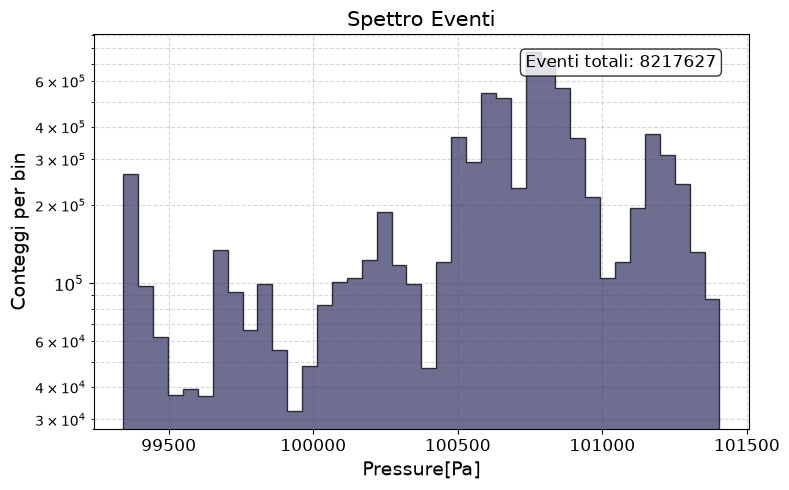

In [8]:
plot_spettro(dati, colonna='Pressure[Pa]', bins=40)

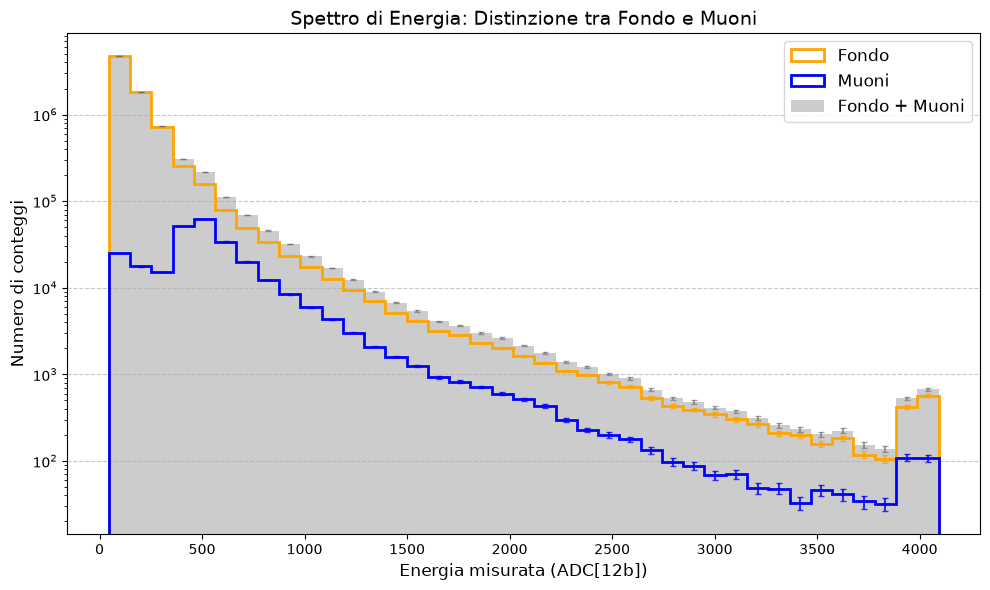

In [9]:
plot_spettro_energia(dati, colonna='ADC[12b]', bins=40)

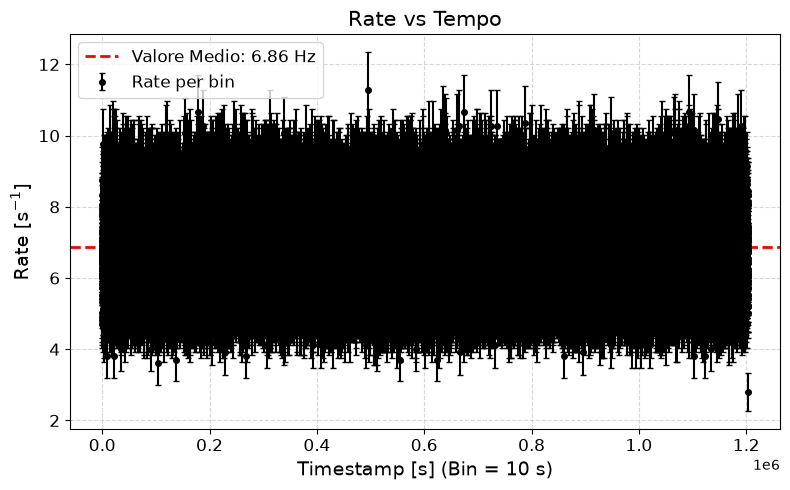

In [10]:
plot_rate_temporale(dati, finestra_temporale_s=10)

Alcune osservazioni su questi grafici:

**1. La scala logaritmica**
In un asse normale (chiamato lineare), ogni tacca aumenta di una quantità fissa: 10, 20, 30, 40... In una **scala logaritmica**, invece, si procede per moltiplicazioni per dieci: 1, 10, 100, 1.000, 10.000...
Perché ci serve?
Immagina di dover rappresentare sullo stesso foglio l'altezza di un grattacielo e lo spessore di una moneta mantenendo le proporzioni: è impossibile.
In fisica succede spesso di avere dati con valori enormi e dati rarissimi con valori bassissimi.
La scala logaritmica "comprime" le grandi distanze, permettendoci di vedere chiaramente sia gli eventi frequentissimi sia quelli che capitano pochissime volte, tutto all'interno dello stesso grafico.

**2. Le barre di errore (la misura della nostra incertezza)**
Se guardi i dati, i punti non sono semplici pallini, ma hanno delle lineette verticali.
Queste sono le **barre di errore**.
In fisica nessuna misura è esatta al 100%.
Quando contiamo eventi casuali (come le particelle di raggi cosmici), c'è sempre una fluttuazione statistica.
Quella barra ci dice: *"Non siamo sicuri che il valore vero sia esattamente al centro del pallino, ma è molto probabile che cada da qualche parte lungo questa linea"*.
Più la barra è corta, più la misura è precisa (perché abbiamo raccolto tanti dati).
Se la barra è molto lunga, significa che per quel punto abbiamo poche informazioni e l'incertezza è alta.

**3. Il "Rebinning"**
Un istogramma è formato da "rettangoli" (chiamati *bin*) in cui infiliamo i nostri dati. Ad esempio, immagina di fare un grafico con le altezze dei tuoi compagni, usando un rettangolo per ogni millimetro (170,1 cm, 170,2 cm, ecc.). Il grafico verrebbe tutto frastagliato, con molti spazi vuoti e punte isolate.
Fare **rebinning** significa allargare questi rettangoli, unendoli a due a due, o a tre a tre (es. un bin unico da 170 a 175 cm).
Il risultato è un compromesso: si sacrifica un po' di risoluzione sui dettagli fini, ma il grafico diventa molto più liscio.
Questo riduce il "rumore" statistico e fa saltare all'occhio la vera forma della distribuzione dei dati.

Prova tu stesso a variare i valori
```python
bins=40
```
```python
finestra_temporale_s=10
```
per vedere cosa succede alle distribuzioni.

## Studi aggiutivi

### 3. Linearità del convertitore ADC vs SiPM

Un grafico che ci permette di verificare visivamente la bontà della conversione interna dell'elettronica.

Mettendo in relazione diretta i valori dell'elettronica (`ADC[12b]`) sull'asse x con la stima della tensione (`SiPM[mV]`) sull'asse y per ciascun evento, possiamo osservare la  **linearità** del rivelatore.

La stessa funzione può mettere in relazione due colonne qualsiasi: sotto la usiamo anche per vedere temperatura e pressione in funzione del tempo e la pressione in funzione della temperatura.

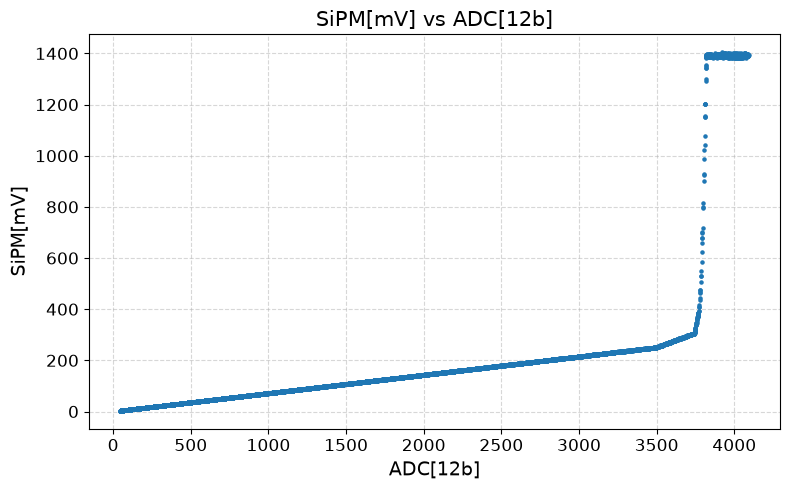

In [11]:
plot_linearita_adc(dati, 'ADC[12b]', 'SiPM[mV]')

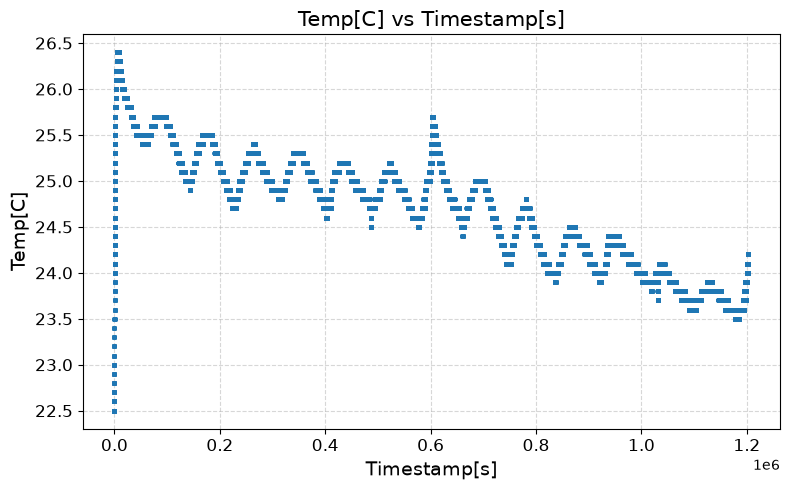

In [12]:
plot_linearita_adc(dati, 'Timestamp[s]', 'Temp[C]')

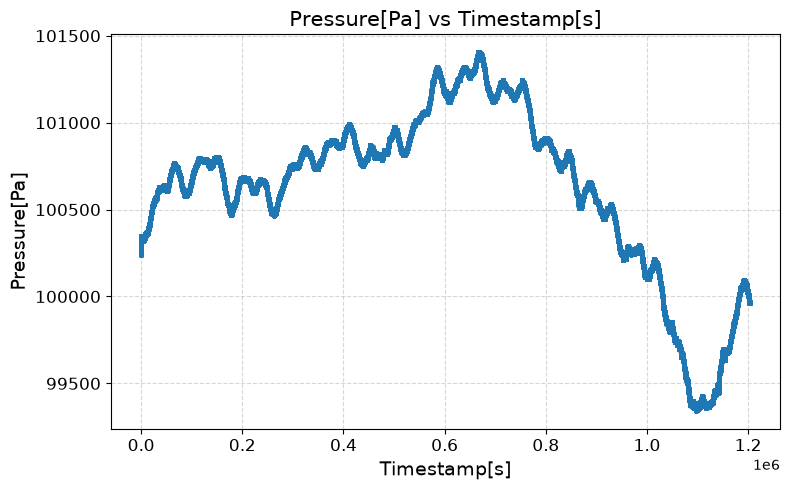

In [13]:
plot_linearita_adc(dati, 'Timestamp[s]', 'Pressure[Pa]')

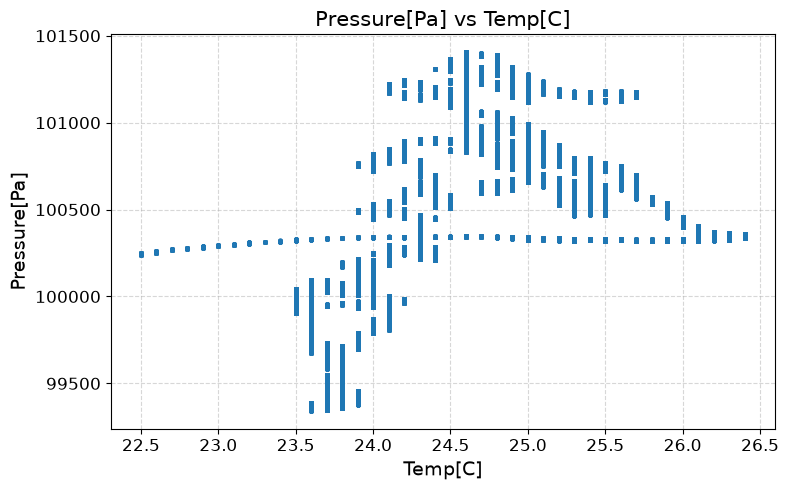

In [14]:
plot_linearita_adc(dati, 'Temp[C]', 'Pressure[Pa]')

In [15]:

import numpy as np
import matplotlib.pyplot as plt

def plot_rate_coincidenze_vs_pressione(dati, finestra_temporale_s=300):

    bin_size_s = float(finestra_temporale_s)

    # Mantieni solo gli eventi coincidenti
    dati = dati[dati['Coincident[bool]'] == True].copy()

    if dati.empty:
        print("Non ci sono eventi coincidenti nei dati.")
        return

    # Estrazione dei dati
    Timestamp = dati['Timestamp[s]'].values
    pressione = dati['Pressure[Pa]'].values

    t_start = Timestamp.min()
    t_end = Timestamp.max()

    # Calcolo del dead time per singolo evento
    deadtime_cum = dati['Deadtime[s]'] - dati['Deadtime[s]'].min()
    event_deadtime = (
        deadtime_cum.diff().fillna(deadtime_cum.iloc[0]).values
    )

    # Creazione dei bin temporali
    bins = np.arange(t_start, t_end + bin_size_s, bin_size_s)

    # Conteggio delle coincidenze in ogni bin
    counts, edges = np.histogram(Timestamp, bins=bins)

    # Dead time totale accumulato per bin
    deadtime_per_bin_s, _ = np.histogram(
        Timestamp, bins=bins, weights=event_deadtime
    )

    # Pressione media per bin
    pressione_somma, _ = np.histogram(
        Timestamp, bins=bins, weights=pressione
    )

    pressione_media = np.divide(
        pressione_somma,
        counts,
        out=np.full(len(counts), np.nan, dtype=float),
        where=counts > 0
    )

    # Calcolo del livetime
    livetime_per_bin = bin_size_s - deadtime_per_bin_s
    livetime_per_bin = np.maximum(livetime_per_bin, 1e-6)

    # Rate corretto per ogni bin
    corrected_rate = counts / livetime_per_bin

    # Esclusione dei bin con rate inferiore a 0.2 Hz
    mask = (
        (corrected_rate >= 0.2) &
        np.isfinite(pressione_media)
    )

    pressione_media = pressione_media[mask]
    corrected_rate = corrected_rate[mask]
    counts_validi = counts[mask]
    livetime_validi = livetime_per_bin[mask]

    if len(corrected_rate) == 0:
        print("Non ci sono bin con rate >= 0.2 Hz.")
        return

    # Rate medio globale sui soli bin validi
    media_rate = counts_validi.sum() / livetime_validi.sum()

    # Variazioni relative rispetto ai valori medi:
    # Delta P = P - P_medio [hPa],  Delta I / I_medio = R / R_medio - 1 [%]
    delta_P = (pressione_media - pressione_media.mean()) / 100
    delta_I = 100 * (corrected_rate / media_rate - 1)

    # Incertezza poissoniana sul rate: sqrt(N) / tempo vivo
    delta_I_err = 100 * np.sqrt(counts_validi) / livetime_validi / media_rate

    # Fit lineare pesato: Delta I / I = beta * Delta P + q
    # la pendenza beta e' il coefficiente barometrico [%/hPa]
    coeff, cov = np.polyfit(delta_P, delta_I, 1, w=1 / delta_I_err, cov='unscaled')
    beta, beta_err = coeff[0], np.sqrt(cov[0, 0])
    chi2 = np.sum(((delta_I - np.polyval(coeff, delta_P)) / delta_I_err) ** 2)
    ndf = len(delta_P) - 2

    x_fit = np.linspace(delta_P.min(), delta_P.max(), 300)
    y_fit = np.polyval(coeff, x_fit)

    # Creazione del grafico
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.set_axisbelow(True)
    ax.grid(which='both', linestyle='--', alpha=0.5)

    # Punti sperimentali con barre di errore
    ax.errorbar(
        delta_P,
        delta_I,
        yerr=delta_I_err,
        fmt='ko',
        markersize=4,
        capsize=2,
        label='Coincidence rate per bin'
    )

    # Retta di fit
    ax.plot(
        x_fit,
        y_fit,
        color='blue',
        linewidth=2,
        label=rf'Fit: $\beta$ = {beta:.3f} $\pm$ {beta_err:.3f} %/hPa'
    )

    # Etichette e titolo
    ax.set_xlabel(r'$\Delta P$ [hPa]', fontsize=14)
    ax.set_ylabel(r'$\Delta I/\bar{I}$ [%]', fontsize=14)

    ax.set_title(
        f'Coincidence rate vs pressure '
        f'(bin = {bin_size_s / 60:.0f} min)',
        fontsize=15
    )

    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.legend(fontsize=11)

    plt.tight_layout()
    plt.show()

    print(f"Pressione media: {pressione_media.mean() / 100:.1f} hPa,  rate medio: {media_rate:.4f} Hz,  bin usati: {len(delta_P)}")
    print(f"Coefficiente barometrico: beta = {beta:.3f} +/- {beta_err:.3f} %/hPa")
    print(f"chi2/ndf = {chi2:.1f}/{ndf}")
    print("Valore nel documento (Fig. 2.14): beta = -0.141 +/- 0.007 %/hPa")

    return beta, beta_err


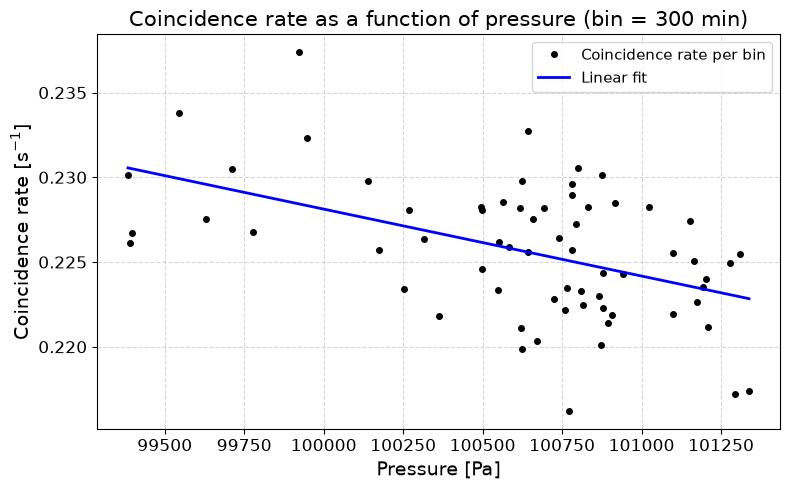

-3.9507125426673e-06
0.6231949572348724


In [16]:
plot_rate_coincidenze_vs_pressione(dati, finestra_temporale_s=18000)

In [17]:

import numpy as np
import matplotlib.pyplot as plt

def plot_rate_coincidenze_vs_tempo(dati, finestra_temporale_s=18000):

    bin_size_s = float(finestra_temporale_s)

    # Mantieni solo gli eventi coincidenti
    dati = dati[dati['Coincident[bool]'] == True].copy()

    if dati.empty:
        print("Non ci sono eventi coincidenti nei dati.")
        return

    # Estrazione dei dati
    Timestamp = dati['Timestamp[s]'].values

    t_start = Timestamp.min()
    t_end = Timestamp.max()

    # Calcolo del dead time per singolo evento
    deadtime_cum = dati['Deadtime[s]'] - dati['Deadtime[s]'].min()

    event_deadtime = (
        deadtime_cum.diff().fillna(deadtime_cum.iloc[0]).values
    )

    # Creazione dei bin temporali
    bins = np.arange(t_start, t_end + bin_size_s, bin_size_s)

    # Conteggio delle coincidenze in ogni bin
    counts, edges = np.histogram(Timestamp, bins=bins)

    # Dead time totale accumulato per bin
    deadtime_per_bin_s, _ = np.histogram(
        Timestamp,
        bins=bins,
        weights=event_deadtime
    )

    # Calcolo del livetime
    livetime_per_bin = bin_size_s - deadtime_per_bin_s
    livetime_per_bin = np.maximum(livetime_per_bin, 1e-6)

    # Rate corretto per ogni bin
    corrected_rate = counts / livetime_per_bin

    # Centro di ogni bin temporale
    tempo_bin = (edges[:-1] + edges[1:]) / 2

    # Esclusione dei bin con rate inferiore a 0.2 Hz
    mask = corrected_rate >= 0.2

    tempo_bin = tempo_bin[mask]
    corrected_rate = corrected_rate[mask]
    counts_validi = counts[mask]
    livetime_validi = livetime_per_bin[mask]

    if len(corrected_rate) == 0:
        print("Non ci sono bin con rate >= 0.2 Hz.")
        return

    # Rate medio globale sui soli bin validi
    media_rate = counts_validi.sum() / livetime_validi.sum()

    # Conversione del tempo in ore rispetto all'inizio della misura
    tempo_ore = (tempo_bin - t_start) / 3600

    # Ordinamento temporale
    ordine = np.argsort(tempo_ore)
    tempo_ore = tempo_ore[ordine]
    corrected_rate = corrected_rate[ordine]

    # Fit lineare
    if len(tempo_ore) >= 2:

        coeff = np.polyfit(tempo_ore, corrected_rate, 1)
        retta = np.poly1d(coeff)

        x_fit = np.linspace(
            tempo_ore.min(),
            tempo_ore.max(),
            300
        )

        y_fit = retta(x_fit)

    # Creazione del grafico
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.set_axisbelow(True)
    ax.grid(which='both', linestyle='--', alpha=0.5)

    # Punti sperimentali
    ax.plot(
        tempo_ore,
        corrected_rate,
        'ko',
        markersize=5,
        label='Coincidence rate per bin'
    )

    # Etichette e titolo
    ax.set_xlabel('Time [hours]', fontsize=14)
    ax.set_ylabel(r'Coincidence rate [s$^{-1}$]', fontsize=14)

    ax.set_title(
        f'Coincidence rate as a function of time '
        f'(bin = {bin_size_s / 3600:.1f} h)',
        fontsize=15
    )

    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.legend(fontsize=11)

    plt.tight_layout()
    plt.show()


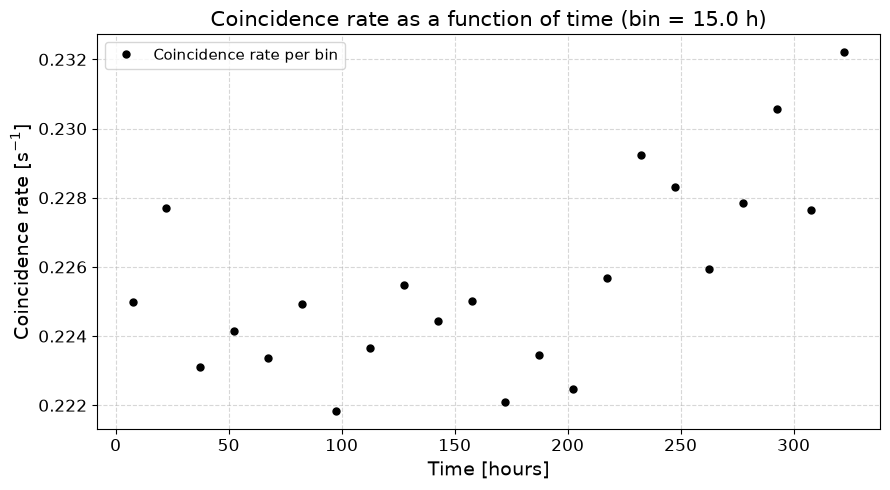

In [18]:
plot_rate_coincidenze_vs_tempo(dati, finestra_temporale_s=54000)

In [19]:

import numpy as np
import matplotlib.pyplot as plt

def plot_pressione_vs_tempo(dati, finestra_temporale_s=18000):

    bin_size_s = float(finestra_temporale_s)

    # Mantieni solo gli eventi coincidenti
    dati = dati[dati['Coincident[bool]'] == True].copy()

    if dati.empty:
        print("Non ci sono eventi coincidenti nei dati.")
        return

    # Estrazione dei dati
    Timestamp = dati['Timestamp[s]'].values
    pressione = dati['Pressure[Pa]'].values

    t_start = Timestamp.min()
    t_end = Timestamp.max()

    # Creazione dei bin temporali
    bins = np.arange(t_start, t_end + bin_size_s, bin_size_s)

    # Conteggio degli eventi in ogni bin
    counts, edges = np.histogram(Timestamp, bins=bins)

    # Somma delle pressioni in ogni bin
    pressione_somma, _ = np.histogram(
        Timestamp,
        bins=bins,
        weights=pressione
    )

    # Pressione media per bin
    pressione_media = np.divide(
        pressione_somma,
        counts,
        out=np.full(len(counts), np.nan, dtype=float),
        where=counts > 0
    )

    # Centro di ogni bin temporale
    tempo_bin = (edges[:-1] + edges[1:]) / 2

    # Mantieni solo i bin con almeno un evento
    mask = counts > 0

    tempo_bin = tempo_bin[mask]
    pressione_media = pressione_media[mask]

    # Conversione del tempo in ore rispetto all'inizio della misura
    tempo_ore = (tempo_bin - t_start) / 3600

    # Ordinamento temporale
    ordine = np.argsort(tempo_ore)
    tempo_ore = tempo_ore[ordine]
    pressione_media = pressione_media[ordine]

    # Creazione del grafico
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.set_axisbelow(True)
    ax.grid(which='both', linestyle='--', alpha=0.5)

    # Punti sperimentali
    ax.plot(
        tempo_ore,
        pressione_media,
        'ko',
        markersize=5,
        label='Average pressure per bin'
    )

    # Etichette e titolo
    ax.set_xlabel('Time [hours]', fontsize=14)
    ax.set_ylabel('Pressure [Pa]', fontsize=14)

    ax.set_title(
        f'Pressure as a function of time '
        f'(bin = {bin_size_s / 3600:.1f} h)',
        fontsize=15
    )

    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.legend(fontsize=11)

    plt.tight_layout()
    plt.show()


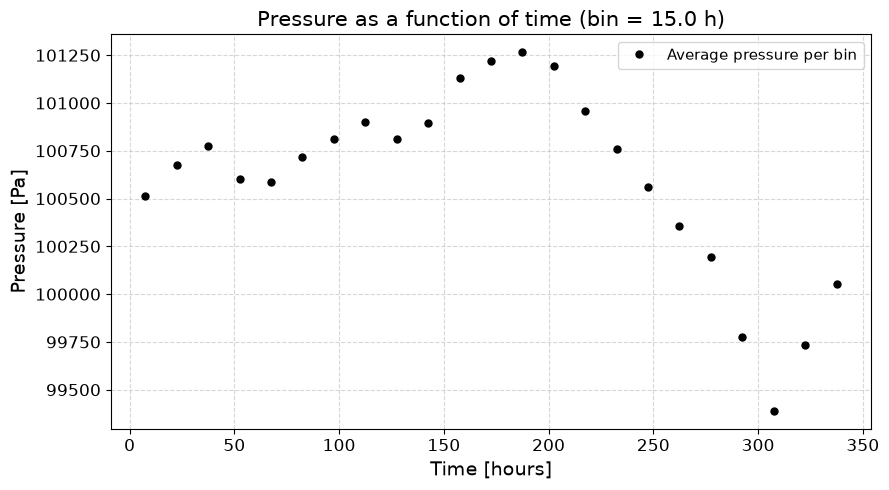

In [20]:
plot_pressione_vs_tempo(dati, finestra_temporale_s=54000)

In [21]:

import numpy as np
import matplotlib.pyplot as plt

def plot_pressione_e_rate_vs_tempo(dati, finestra_temporale_s=18000):

    bin_size_s = float(finestra_temporale_s)

    # Mantieni solo gli eventi coincidenti
    dati = dati[dati['Coincident[bool]'] == True].copy()

    if dati.empty:
        print("Non ci sono eventi coincidenti nei dati.")
        return

    # Estrazione dei dati
    Timestamp = dati['Timestamp[s]'].values
    pressione = dati['Pressure[Pa]'].values

    t_start = Timestamp.min()
    t_end = Timestamp.max()

    # Calcolo del dead time per singolo evento
    deadtime_cum = dati['Deadtime[s]'] - dati['Deadtime[s]'].min()

    event_deadtime = (
        deadtime_cum.diff().fillna(deadtime_cum.iloc[0]).values
    )

    # Creazione dei bin temporali
    bins = np.arange(t_start, t_end + bin_size_s, bin_size_s)

    # Conteggio degli eventi per bin
    counts, edges = np.histogram(Timestamp, bins=bins)

    # -----------------------------
    # CALCOLO PRESSIONE MEDIA
    # -----------------------------

    pressione_somma, _ = np.histogram(
        Timestamp,
        bins=bins,
        weights=pressione
    )

    pressione_media = np.divide(
        pressione_somma,
        counts,
        out=np.full(len(counts), np.nan, dtype=float),
        where=counts > 0
    )

    # -----------------------------
    # CALCOLO RATE CORRETTO
    # -----------------------------

    deadtime_per_bin_s, _ = np.histogram(
        Timestamp,
        bins=bins,
        weights=event_deadtime
    )

    livetime_per_bin = bin_size_s - deadtime_per_bin_s
    livetime_per_bin = np.maximum(livetime_per_bin, 1e-6)

    corrected_rate = counts / livetime_per_bin

    # -----------------------------
    # CENTRO DEI BIN TEMPORALI
    # -----------------------------

    tempo_bin = (edges[:-1] + edges[1:]) / 2

    tempo_ore = (tempo_bin - t_start) / 3600

    # -----------------------------
    # SELEZIONE DEI BIN
    # -----------------------------

    # Pressione: almeno un evento
    mask_pressione = counts > 0

    # Rate: almeno 0.2 Hz
    mask_rate = corrected_rate >= 0.2

    tempo_pressione = tempo_ore[mask_pressione]
    pressione_valida = pressione_media[mask_pressione]

    tempo_rate = tempo_ore[mask_rate]
    rate_valido = corrected_rate[mask_rate]

    # -----------------------------
    # CREAZIONE DEL GRAFICO
    # -----------------------------

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Secondo asse y
    ax2 = ax1.twinx()

    ax1.set_axisbelow(True)
    ax1.grid(which='both', linestyle='--', alpha=0.5)

    # Pressione - asse sinistro
    p1 = ax1.plot(
        tempo_pressione,
        pressione_valida,
        'bo-',
        markersize=5,
        linewidth=1.5,
        label='Average pressure'
    )

    # Rate - asse destro
    p2 = ax2.plot(
        tempo_rate,
        rate_valido,
        'ro-',
        markersize=5,
        linewidth=1.5,
        label='Coincidence rate'
    )

    # Etichette degli assi
    ax1.set_xlabel('Time [hours]', fontsize=14)

    ax1.set_ylabel(
        'Pressure [Pa]',
        fontsize=14,
        color='blue'
    )

    ax2.set_ylabel(
        r'Coincidence rate [s$^{-1}$]',
        fontsize=14,
        color='red'
    )

    # Colori dei tick
    ax1.tick_params(axis='y', labelcolor='blue', labelsize=12)
    ax2.tick_params(axis='y', labelcolor='red', labelsize=12)
    ax1.tick_params(axis='x', labelsize=12)

    # Titolo
    ax1.set_title(
        f'Pressure and coincidence rate as functions of time '
        f'(bin = {bin_size_s / 3600:.1f} h)',
        fontsize=15
    )

    # Legenda unica per entrambi gli assi
    lines = p1 + p2
    labels = [line.get_label() for line in lines]

    ax1.legend(lines, labels, loc='best', fontsize=11)

    plt.tight_layout()
    plt.show()



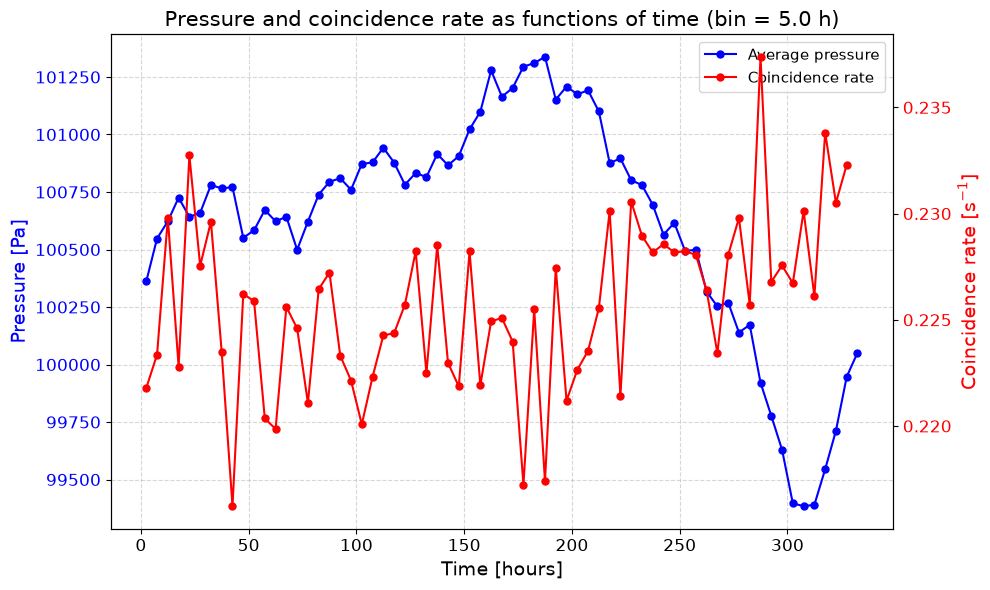

In [22]:
plot_pressione_e_rate_vs_tempo(
    dati,
    finestra_temporale_s=18000
)

---

# Correlazione tra rate dei muoni e pressione atmosferica (Fig. 2.14 di *The Example Measurements*)

Il flusso di muoni al livello del suolo dipende dalla quantità di atmosfera che hanno dovuto attraversare: quando la pressione è più alta c'è "più aria" sopra di noi, i muoni vengono prodotti più in alto, percorrono più strada e ne decadono o vengono assorbiti di più. Il risultato è che **il rate diminuisce quando la pressione aumenta**.

Per piccole variazioni la relazione è lineare:
$$
\frac{\Delta I}{\bar I} = \beta\,\Delta P
$$

* $\Delta I/\bar I = (R - \bar R)/\bar R$ è la variazione relativa del rate di coincidenza rispetto al valore medio (in %);
* $\Delta P = P - \bar P$ è la variazione di pressione rispetto alla media (in hPa);
* $\beta$ è il **coefficiente barometrico** (in %/hPa), che ci aspettiamo negativo. Nel documento si trova $\beta = -0.141 \pm 0.007$ %/hPa.

La funzione `plot_figura_2_14()`:

1. divide la presa dati in bin temporali di durata fissa (2 ore, come nella figura), tenendo **solo i bin completi** (l'ultimo bin, più corto, avrebbe un rate sbagliato);
2. per ogni bin calcola il rate di coincidenza corretto per il tempo morto, $R = N_{coinc}/t_{vivo}$, con incertezza poissoniana $\sqrt{N_{coinc}}/t_{vivo}$, e la pressione media misurata dal sensore BMP280;
3. fa un **fit lineare pesato** di $\Delta I/\bar I$ in funzione di $\Delta P$: la pendenza è $\beta$;
4. disegna a sinistra la distribuzione dei bin nel piano ($\Delta P$, $\Delta I/\bar I$) con la retta di fit, e a destra rate e pressione in funzione del tempo.

Prova a cambiare la durata del bin: come cambiano il grafico e l'incertezza su $\beta$?

In [23]:
# ==============================================================================
# FIGURA 2.14: CORRELAZIONE RATE DI COINCIDENZA - PRESSIONE
# ==============================================================================
def plot_figura_2_14(dati, finestra_temporale_s=7200, gridsize=15):
    bin_size_s = float(finestra_temporale_s)

    # Tempi di tutti gli eventi (servono per tempo morto e pressione)
    Timestamp = dati['Timestamp[s]'].values
    t_start = Timestamp.min()

    # Solo bin temporali completi: l'ultimo bin parziale viene scartato
    n_bin = int((Timestamp.max() - t_start) // bin_size_s)
    bins = t_start + bin_size_s * np.arange(n_bin + 1)

    # Tempo morto per evento (differenza del tempo morto cumulativo) e tempo vivo per bin
    deadtime_cum = dati['Deadtime[s]'].values
    event_deadtime = np.diff(deadtime_cum, prepend=deadtime_cum[0])
    deadtime_per_bin_s, _ = np.histogram(Timestamp, bins=bins, weights=event_deadtime)
    livetime_per_bin = bin_size_s - deadtime_per_bin_s

    # Pressione media per bin [hPa], mediata su tutti gli eventi del bin
    eventi_per_bin, _ = np.histogram(Timestamp, bins=bins)
    pressione_somma, _ = np.histogram(Timestamp, bins=bins, weights=dati['Pressure[Pa]'].values / 100)
    pressione_media = pressione_somma / eventi_per_bin

    # Rate di coincidenza per bin con incertezza poissoniana
    t_coinc = Timestamp[dati['Coincident[bool]'].values == 1]
    counts, _ = np.histogram(t_coinc, bins=bins)
    rate = counts / livetime_per_bin
    rate_err = np.sqrt(counts) / livetime_per_bin
    media_rate = counts.sum() / livetime_per_bin.sum()

    # Variazioni relative: Delta I / I_medio [%] e Delta P [hPa]
    delta_P = pressione_media - pressione_media.mean()
    delta_I = 100 * (rate / media_rate - 1)
    delta_I_err = 100 * rate_err / media_rate

    # Fit lineare pesato: delta_I = beta * delta_P + q
    coeff, cov = np.polyfit(delta_P, delta_I, 1, w=1 / delta_I_err, cov='unscaled')
    beta, beta_err = coeff[0], np.sqrt(cov[0, 0])
    chi2 = np.sum(((delta_I - np.polyval(coeff, delta_P)) / delta_I_err) ** 2)
    ndf = len(delta_P) - 2

    tempo_giorni = ((bins[:-1] + bins[1:]) / 2 - t_start) / 86400

    # --- Grafici ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Sinistra: Delta I / I vs Delta P
    hb = ax1.hexbin(delta_P, delta_I, gridsize=gridsize, cmap='Blues_r')
    fig.colorbar(hb, ax=ax1, label='Numero di bin temporali')
    x_fit = np.linspace(delta_P.min(), delta_P.max(), 100)
    ax1.plot(x_fit, np.polyval(coeff, x_fit), 'w--', linewidth=2.5,
             label=rf'$\beta$ = {beta:.3f} $\pm$ {beta_err:.3f} %/hPa')
    ax1.set_xlabel(r'$\Delta P$ [hPa]', fontsize=14)
    ax1.set_ylabel(r'$\Delta I/\bar{I}$ [%]', fontsize=14)
    ax1.tick_params(axis='both', which='major', labelsize=12)
    ax1.legend(loc='upper right', fontsize=11)

    # Destra: rate (asse sinistro) e pressione (asse destro) vs tempo
    ax2.plot(tempo_giorni, rate, 'k-', linewidth=1)
    ax2.set_xlabel("Tempo dall'inizio della misura [giorni]", fontsize=14)
    ax2.set_ylabel('Rate di coincidenza [Hz]', fontsize=14)
    ax2.tick_params(axis='both', which='major', labelsize=12)
    ax3 = ax2.twinx()
    ax3.plot(tempo_giorni, pressione_media, 'r-', linewidth=2)
    ax3.set_ylabel('Pressione atmosferica [hPa]', fontsize=14, color='red')
    ax3.tick_params(axis='y', labelcolor='red', labelsize=12)

    fig.suptitle(f'Correlazione rate - pressione (bin = {bin_size_s / 3600:.1f} h)', fontsize=15)
    plt.tight_layout()
    plt.show()

    print(f"Numero di bin: {len(delta_P)},  rate medio: {media_rate:.4f} Hz,  "
          f"conteggi medi per bin: {counts.mean():.0f}")
    print(f"Coefficiente barometrico: beta = {beta:.3f} +/- {beta_err:.3f} %/hPa")
    print(f"chi2/ndf = {chi2:.1f}/{ndf}")
    print("Valore nel documento (Fig. 2.14): beta = -0.141 +/- 0.007 %/hPa")

    return beta, beta_err

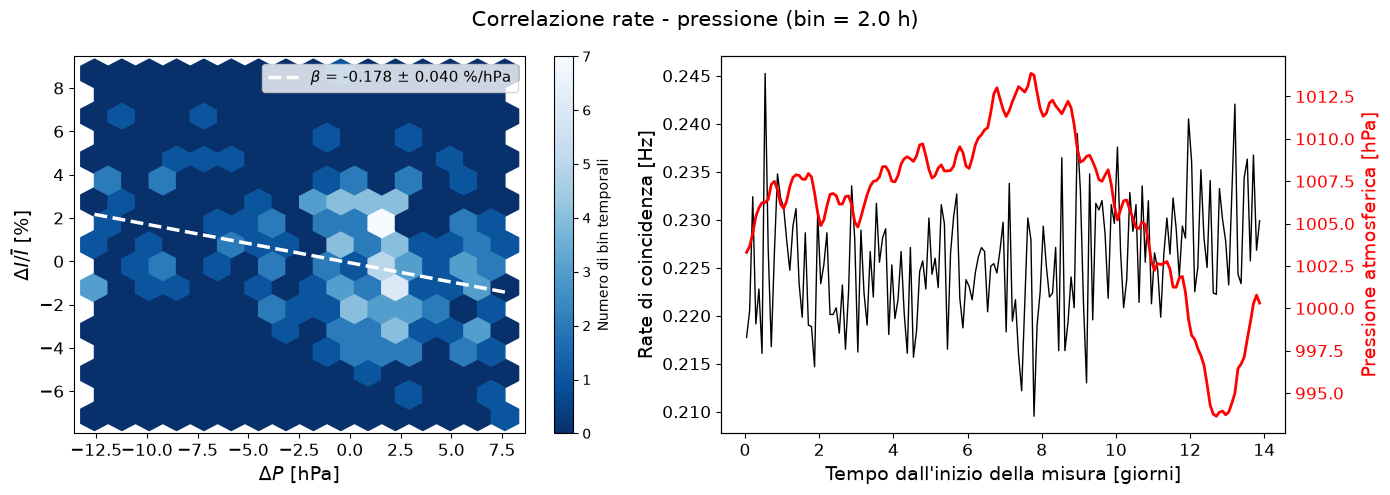

Numero di bin: 167,  rate medio: 0.2257 Hz,  conteggi medi per bin: 1618
Coefficiente barometrico: beta = -0.178 +/- 0.040 %/hPa
chi2/ndf = 178.3/165
Valore nel documento (Fig. 2.14): beta = -0.141 +/- 0.007 %/hPa


In [24]:
beta, beta_err = plot_figura_2_14(dati, finestra_temporale_s=7200)